# Logistic Map and Boundary Crisis Scaling

The **logistic map** is a one-dimensional nonlinear discrete-time system defined by

$$
x_{n+1}=\mu x_n(1-x_n),
$$

where $x_n \in [0,1]$ is the state variable and $\mu$ is the bifurcation parameter. 

## Scaling of Chaotic Transients

Following a **boundary crisis**, trajectories no longer remain on the chaotic attractor indefinitely. Instead, they exhibit **chaotic transients**, spending a finite time near the remnant (ghost) of the destroyed attractor before escaping.

The average transient lifetime follows the power-law scaling

$$
\langle \tau \rangle = (\mu-\mu_c)^{-\gamma},
$$

where

- $\mu_c$ is the critical parameter value,
- $\langle \tau \rangle$ is the average transient lifetime over many initial conditions,
- $\gamma$ is the scaling exponent ($\gamma=\frac{1}{2}$ for logistic map)

## Numerical Procedure

To estimate the scaling exponent:

1. Select parameter values slightly above the crisis point ($\mu>\mu_c$).
2. Sample a large number of random initial conditions.
3. For each initial condition, iterate the map until the trajectory escapes the chaotic region.
4. Record the transient lifetime $\tau$.
5. Compute the average transient lifetime $\langle\tau\rangle$.


[np.float64(130.07896)]
[np.float64(130.07896), np.float64(92.56402)]
[np.float64(130.07896), np.float64(92.56402), np.float64(39.69302)]
[np.float64(130.07896), np.float64(92.56402), np.float64(39.69302), np.float64(27.26504)]
[np.float64(130.07896), np.float64(92.56402), np.float64(39.69302), np.float64(27.26504), np.float64(10.91468)]
[np.float64(130.07896), np.float64(92.56402), np.float64(39.69302), np.float64(27.26504), np.float64(10.91468), np.float64(7.38204)]
Slope: -0.543243312259535
Intercept: 0.7719952275646458


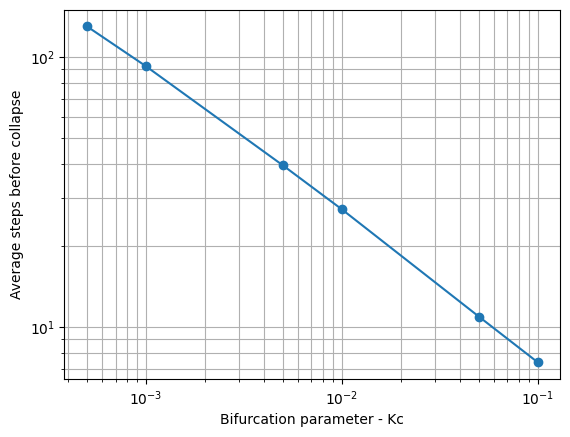

In [2]:
import numpy as np
import matplotlib.pyplot as plt


bif_array_logmap = np.array([4.0005, 4.001, 4.005, 4.01, 4.05, 4.1 ])

ttimesteps = 500
xx_initial = 0.5
cc = 0.3
nnum_trials = 50000
tthreshold = 0

# Precompute once to avoid inside loop
def simulate_single_perturb_logmap(bif_param):
    x_init = xx_initial + np.random.uniform(-cc, cc)
    
    for k in range(ttimesteps):
        x_init = bif_param * x_init * (1 - x_init)  # logistic map rule
        if x_init < tthreshold:                      # break early
            return k                                # store crossing point

    return ttimesteps  # only reached if condition never met


scaling_list_avg_logmap = []
for bif_param in bif_array_logmap:

    rresults = []
    for p in range(nnum_trials):
        rresult = simulate_single_perturb_logmap(bif_param)
        rresults.append(rresult)
    scaling_list_avg_logmap.append(np.mean(rresults))

    print(scaling_list_avg_logmap)


bif_array_shift_logmap = bif_array_logmap - 4
x = np.log(bif_array_shift_logmap)
y = np.log(scaling_list_avg_logmap)

slope, intercept = np.polyfit(x, y, 1)

print("Slope:", slope)
print("Intercept:", intercept)
# Plot
plt.loglog(bif_array_shift_logmap, scaling_list_avg_logmap, marker='o', linestyle='-')
plt.xlabel("Bifurcation parameter - Kc")
plt.ylabel("Average steps before collapse")
plt.grid(True, which='both')
plt.show()

## The natural invariant density of logistic map

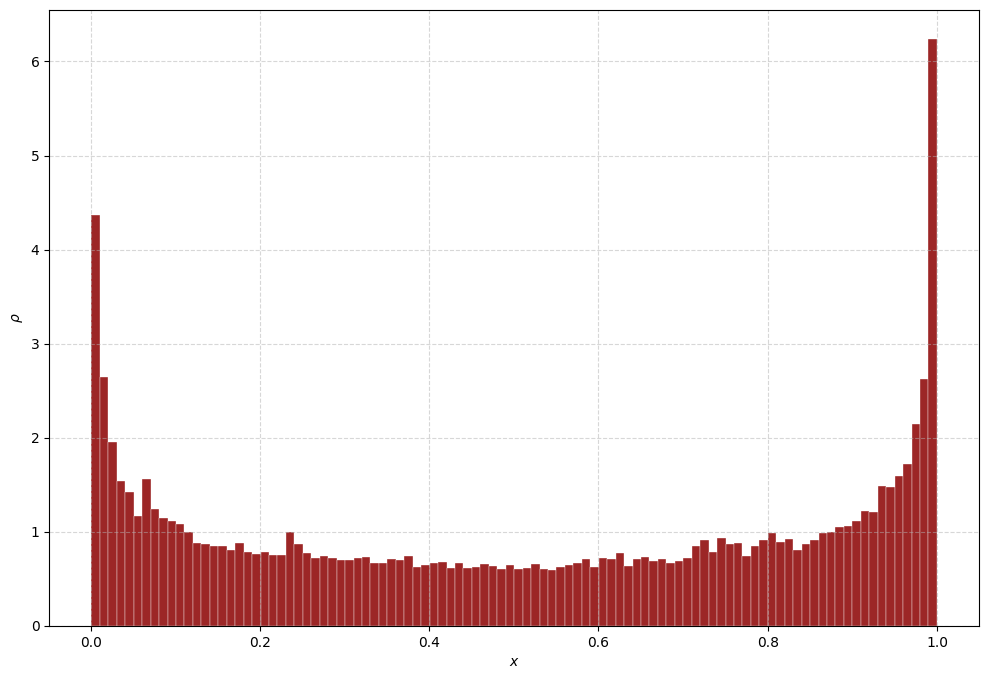

In [3]:
# Parameters
r = 3.999              # Chaotic regime
x0 = 0.3             # Initial condition
n_iter = 50000     # Total iterations
transient = 100     # Discard initial transients

x0_list = []


for _ in range(n_iter):
    x0 = r * x0 * (1 - x0)
    x0_list.append(x0)

x_long = x0_list[transient:]

plt.figure(figsize=(12, 8))
plt.hist(x_long, bins=100, density=True,
         color='darkred', alpha=0.85, edgecolor='white', linewidth=0.3)

plt.xlabel(r"$x$")
plt.ylabel(r"$\rho$")

plt.grid(True, linestyle='--', alpha=0.5)

plt.show()


## The return map plot

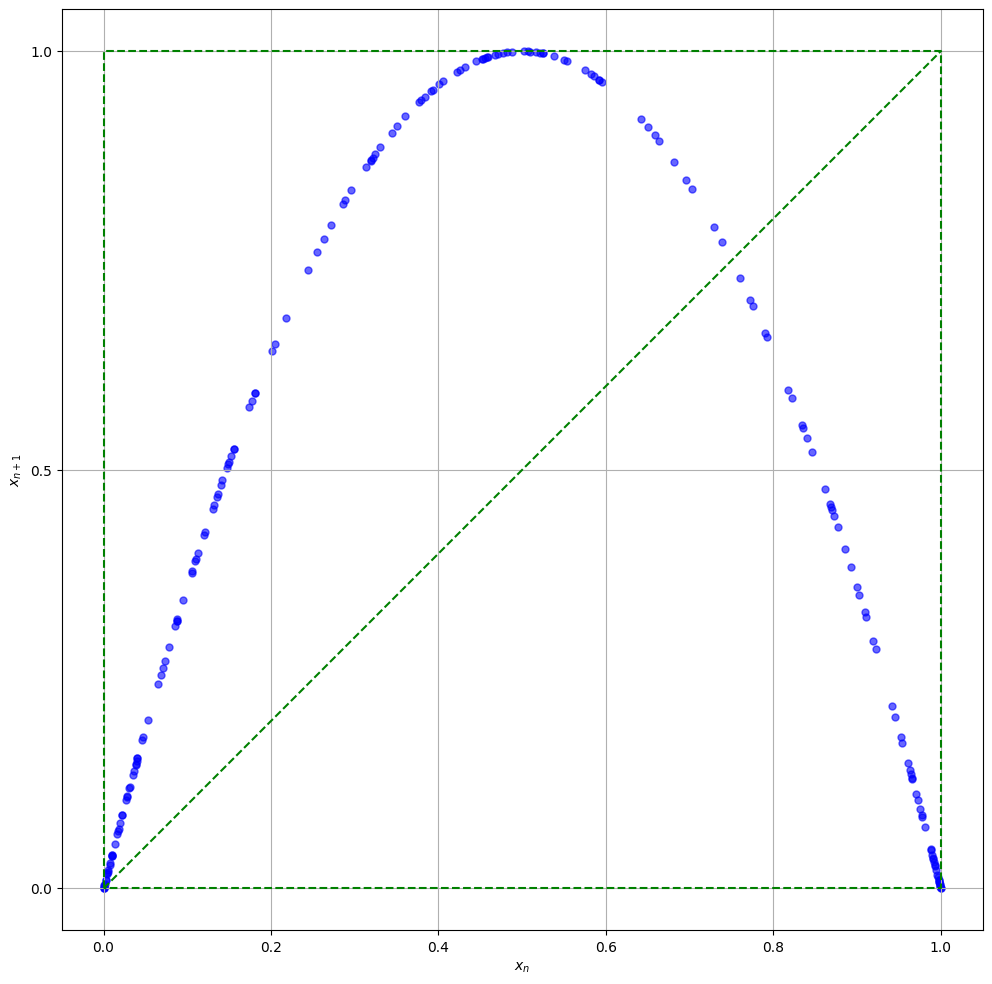

In [4]:
import numpy as np

epsilon_diff = 0.0001

og_bif = 4 + epsilon_diff

m_log = 200

# Return map of original logistic equation

initial_cond = 0.3
logistic_list = []

for i in range(m_log):
    initial_cond = og_bif *(initial_cond)*(1 - initial_cond)
    logistic_list.append(initial_cond)

logistic_array = np.array(logistic_list)


# Prepare return map coordinates: (x_n, x_{n+1})
x_log = logistic_array[:-1]
y_log = logistic_array[1:]


# Plotting
plt.figure(figsize=(10, 10))

# Logistic map return map (larger points)
plt.scatter(x_log, y_log, color='blue', alpha=0.6,
            label='Logistic Map', s=25)  # was s=10


# Square box and diagonal
plt.plot([0, 1], [0, 1], ls='--', color='green', linewidth=1.5, label='y = x')  # Diagonal
plt.plot([0, 0, 1, 1, 0], [0, 1, 1, 0, 0], ls='--', color='green', linewidth=1.5)  # Square boundary


plt.yticks(np.linspace(0, 1, 3))
plt.xlabel(r'$x_n$')
plt.ylabel(r'$x_{n+1}$')
#plt.legend()
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')  # Make it square
plt.tight_layout()

plt.show()
